In [1]:
# export XLA_FLAGS="--xla_gpu_cuda_data_dir=${CUDA_HOME}"

In [ ]:
# import os
# os.environ['JAX_PLATFORMS'] = 'cpu'

import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
os.environ["XLA_FLAGS"] = f"--xla_gpu_cuda_data_dir={os.environ.get('CUDA_HOME', '')}"

# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from tqdm import tqdm
from pathlib import Path

print(jax.devices())
# jax.config.update("jax_debug_nans", True)

from config import Config
import data

In [ ]:
cfg = Config.from_file("/nas/cee-water/cjgleason/ted/swot-ml/runs/test/swot_vD.yml")
cfg.quiet = False

In [ ]:
train_dataset = data.MCFLIDataset(cfg, 'train', 0, True, True)
train_loader = data.MCFLIDataLoader(cfg, train_dataset)

In [ ]:
test_dataset = data.MCFLIDataset(cfg, 'test', 0, True, True)
test_loader = data.MCFLIDataLoader(cfg, test_dataset)

In [6]:
import equinox as eqx
import jax
import jax.numpy as jnp

class SimpleNet(eqx.Module):
    net: eqx.nn.MLP
    n_components: int
    n_samples: int

    def __init__(self, in_size, hidden_size, depth, n_components=4, n_samples=32, *, key):
        self.n_components = n_components
        self.n_samples = n_samples
        
        self.net = eqx.nn.MLP(
            in_size=in_size,
            out_size=2,
            width_size=hidden_size,
            depth=depth,
            key=key
        )

    def __call__(self, x_d, d_mask, x_s, hws, key):
        def forward_t(xd_t):
            feat = jnp.concat([xd_t, x_s])
            return self.net(feat)

        out = jax.vmap(forward_t)(x_d)
        mean_q, log_std_q = out[:, 0], out[:, 1]
        
        std_q = jnp.exp(jnp.clip(log_std_q, -6, 2))

        noise = jax.random.normal(key, shape=(self.n_samples, x_d.shape[0]))
        Q_samples = mean_q[None, :] + std_q[None, :] * noise

        Q_samples = jnp.where(d_mask[None, :], Q_samples, 0.0)
        Q_samples = jnp.maximum(Q_samples, 0.0)

        dummy_A0 = jnp.zeros(self.n_samples)
        dummy_n = jnp.zeros(self.n_samples)

        return Q_samples, dummy_A0, dummy_n

In [20]:
import equinox as eqx
import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp

class MixtureHead(eqx.Module):
    net: eqx.nn.MLP
    n_components: int

    def __init__(self, in_size, hidden_size, depth, n_components, *, key):
        self.n_components = n_components
        # Outputs: n_components * (weight_logit, mean, log_std)
        self.net = eqx.nn.MLP(
            in_size=in_size,
            out_size=n_components * 3,
            width_size=hidden_size,
            depth=depth,
            key=key
        )

    def __call__(self, x):
        out = self.net(x)
        logits, means, log_stds = jnp.split(out, 3, axis=-1)
        log_weights = jax.nn.log_softmax(logits, axis=-1)   # (K,)
        log_stds = jnp.clip(log_stds, -6, 0)               # numerical stability
        return log_weights, means, log_stds

    def sample(self, x, key):
        log_weights, means, log_stds = self(x)
        k1, k2 = jax.random.split(key)
        # Gumbel-max trick to sample component
        component = jnp.argmax(
            log_weights + jax.random.gumbel(k1, shape=log_weights.shape)
        )
        mean = means[component]
        std = jnp.exp(log_stds[component])
        return mean + std * jax.random.normal(k2, shape=mean.shape)

    def mean(self, x):
        """E[x] = sum_k w_k * mu_k"""
        log_weights, means, _ = self(x)
        return jnp.sum(jnp.exp(log_weights) * means)

    def log_prob(self, x, value):
        """Log likelihood of a scalar value under the mixture."""
        log_weights, means, log_stds = self(x)
        stds = jnp.exp(log_stds)
        log_component_probs = (
            -0.5 * ((value - means) / stds) ** 2
            - log_stds
            - 0.5 * jnp.log(2 * jnp.pi)
        )
        return logsumexp(log_weights + log_component_probs)

        
        
class ReachParameterNet(eqx.Module):
    A0_head: MixtureHead
    n_head: MixtureHead
    n_components: int
    n_samples: int

    def __init__(self, in_size, hidden_size, depth, n_components=4, n_samples=32, *, key):
        k1, k2 = jax.random.split(key)
        self.n_components = n_components
        self.n_samples = n_samples
        self.A0_head = MixtureHead(in_size, hidden_size, depth, n_components, key=k1)
        self.n_head  = MixtureHead(in_size, hidden_size, depth, n_components, key=k2)

    def __call__(self, x_d, d_mask, x_s, hws, key):
        def get_gmm_params(x_temporal):
            feat = jnp.concat([x_temporal, x_s])
            return self.A0_head(feat), self.n_head(feat)
    
        all_A0_gmm, all_n_gmm = jax.vmap(get_gmm_params)(x_d)
    
        k1, k2 = jax.random.split(key)
        A0_samples = self._sample_gmm_all(all_A0_gmm, k1)  # (T, S)
        n_samples  = self._sample_gmm_all(all_n_gmm,  k2)  # (T, S)
    
        # If all timesteps masked, mean is undefined — default to 0
        n_valid = jnp.sum(d_mask)
        mask = d_mask[:, None]
    
        A0_latent = jnp.where(n_valid > 0,
                        jnp.sum(A0_samples * mask, axis=0) / jnp.maximum(n_valid, 1),
                        jnp.zeros(self.n_samples))
        n_latent  = jnp.where(n_valid > 0,
                        jnp.sum(n_samples  * mask, axis=0) / jnp.maximum(n_valid, 1),
                        jnp.zeros(self.n_samples))
    
        dh, w, s = hws[:, 0], hws[:, 1], hws[:, 2]
        dA    = w * dh
        avg_w = jnp.sum(w * d_mask) / jnp.maximum(n_valid, 1)  # safe masked mean
        min_dA = jnp.min(dA)  # can be -inf if dA has bad values 
        min_dA = jnp.where(jnp.isfinite(min_dA), min_dA, 0.0)
    
        def manning(a0_lat, n_lat):
            # Clamp before any nonlinear transform
            a0_lat = jnp.clip(a0_lat, -5.0, 5.0)
            n_lat  = jnp.clip(n_lat,  -5.0, 5.0)
            A0 = (jax.nn.softplus(a0_lat) * avg_w) - min_dA + 1e-6
            A  = A0 + dA
            # Guard negative areas before fractional power
            A  = jnp.clip(A, 1e-6, None)
            n  = 0.3 + 0.299 * jnp.tanh(n_lat)
            Q  = (1/n) * jnp.power(A, 5/3) * jnp.power(w, -2/3) * jnp.sqrt(s)
            # Final guard — don't let Q explode into the loss
            Q  = jnp.clip(Q, 0.0, 1e8)
            return Q, A0, n
    
        Q_samples, A0_out, n_out = jax.vmap(manning)(A0_latent, n_latent)
        return Q_samples, A0_out, n_out


    def _sample_gmm_all(self, gmm_params, key):
        """Sample S values from each of T GMMs. Returns (T, S)."""
        log_weights, means, log_stds = gmm_params  # each (T, K)
        T = means.shape[0]
        keys = jax.random.split(key, T)

        def sample_one(lw, mu, ls, k):
            # Draw S samples from a single K-component GMM
            k1, k2 = jax.random.split(k)
            # (S,) component indices via Gumbel-max
            gumbels = jax.random.gumbel(k1, shape=(self.n_samples, self.n_components))
            components = jnp.argmax(lw[None, :] + gumbels, axis=-1)  # (S,)
            # Gather means and stds for selected components
            sel_mu  = mu[components]               # (S,)
            sel_std = jnp.exp(ls[components])      # (S,)
            samples = sel_mu + sel_std * jax.random.normal(k2, shape=(self.n_samples,))
            # Clamp latent samples to a sane range before physics transforms
            return jnp.clip(samples, -5.0, 5.0)

        return jax.vmap(sample_one)(log_weights, means, log_stds, keys)  # (T, S)


def probabilistic_loss(model, x_d, d_mask, x_s, hws, y, norm_fn, key):
    keys = jax.random.split(key, x_d.shape[0])
    Q_samples, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws, keys)
    # Q_samples: (B, S, num_reaches)

    y_hat = jax.vmap(jax.vmap(norm_fn))(Q_samples)  # (B, S, num_reaches)

    mu_q  = jnp.mean(y_hat, axis=1)           # (B, num_reaches)
    var_q = jnp.mean((y_hat - mu_q[:, None, :]) ** 2, axis=1)
    std_q = jnp.sqrt(var_q + 1e-6)            # fused for numerical stability

    err = (y - mu_q) / std_q
    nll = jnp.log(std_q) + 0.5 * err**2

    valid = d_mask & jnp.isfinite(nll)
    return jnp.sum(jnp.where(valid, nll, 0.0)) / jnp.maximum(jnp.sum(valid), 1)

In [7]:
def summarize_predictions(Q_samples, A0_samples, n_samples):
    q_mean = jnp.median(Q_samples, axis=1)
    q_low  = jnp.percentile(Q_samples, 5, axis=1)
    q_high = jnp.percentile(Q_samples, 95, axis=1)
    a0_est = jnp.median(A0_samples, axis=1)
    n_est  = jnp.median(n_samples, axis=1)
    
    return {
        "Q_mean": q_mean,
        "Q_low": q_low,
        "Q_high": q_high,
        "A0_static": a0_est,
        "n_static": n_est
    }

In [8]:
sample = train_dataset[0]
d_size = sample['x_d'].shape[-1]
s_size = sample['x_s'].shape[-1]

in_size = d_size + s_size
out_size = 1

In [8]:
sample['x_d'].shape

(200, 18)

In [31]:
for batch in train_loader:
    basin, subbasin, x_d, d_mask, x_s, hws, y = batch
    d_mask = d_mask[..., 0] #bandaid
    y = y[...,0]
    break

key = jax.random.PRNGKey(0)
tmp_model = ReachParameterNet(in_size, 64, 4, key=key)
# tmp_model = SimpleNet(in_size, 64, 4, key=key)

batch_keys = jax.random.split(key, 256)
y_hat, A0, n = jax.vmap(tmp_model)(x_d, d_mask, x_s, hws, key=batch_keys)

In [11]:
x_d.shape

(256, 200, 18)

In [12]:
d_mask.shape

(256, 200)

In [13]:
x_s.shape

(256, 1)

In [14]:
hws.shape

(256, 200, 3)

In [16]:
key = jax.random.PRNGKey(0)
# model = ReachParameterNet(in_size, 64, 4, key=key)
model = SimpleNet(in_size, 64, 4, key=key)

keys = jax.random.split(key, x_d.shape[0])

y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws, key=keys)#[...,0].shape

In [19]:
d_mask.shape

(256, 200)

In [20]:
hws.shape

(256, 200, 3)

In [21]:
hws[...,0].shape

(256, 200)

In [37]:
import optax
from functools import partial

jax.config.update("jax_debug_nans", True)

keys = jax.random.split(jax.random.PRNGKey(0))
# model = ReachParameterNet(in_size, 64, 4, key=key)
model = ReachParameterNet(in_size, 256, 4, key=keys[0])
# model = SimpleNet(in_size, 64, 4, key=keys[0])

optim = optax.adamw(learning_rate=0.0001, weight_decay=0.1)
trainable_model = eqx.filter(model, eqx.is_array)
opt_state = optim.init(trainable_model)


@eqx.filter_jit
def make_step(model, x_d, d_mask, x_s, hws, y, norm_fn, denorm_fn, opt_state, key):
    # loss, grads = eqx.filter_value_and_grad(log_mse_loss)(model, x_d, d_mask, x_s, hws, y, norm_fn)
    # loss, grads = eqx.filter_value_and_grad(log_mae_loss)(model, x_d, d_mask, x_s, hws, y, norm_fn)
    # loss, grads = eqx.filter_value_and_grad(nse_loss)(model, x_d, d_mask, x_s, hws, y, denorm_fn)
    loss, grads = eqx.filter_value_and_grad(probabilistic_loss)(model, x_d, d_mask, x_s, hws, y, norm_fn, key)
    updates, opt_state = optim.update(grads, opt_state, params=model)
    model = eqx.apply_updates(model, updates)
    return loss, model, opt_state


train_losses = []
test_losses = []
target_norm_fn = partial(train_dataset.normalize, name='discharge')
target_denorm_fn = partial(train_dataset.denormalize, name='discharge')

epoch_iter = tqdm(range(250), desc='Epoch:')
for epoch in epoch_iter:
    e_losses = []
    for batch in train_loader:
        basin, subbasin, x_d, d_mask, x_s, hws, y = batch
        d_mask = d_mask[..., 0] #bandaid
        y = y[...,0]
        step_key = keys[1]
        keys = jax.random.split(keys[0])

        loss, model, opt_state = make_step(model, x_d, d_mask, x_s, hws, y, target_norm_fn, target_denorm_fn, opt_state, step_key)
        e_losses.append(loss.item())
        
    train_losses.append(np.mean(e_losses))


    e_losses = []
    for batch in test_loader:
        basin, subbasin, x_d, d_mask, x_s, hws, y = batch
        d_mask = d_mask[..., 0] #bandaid
        y = y[...,0]

        # loss = eqx.filter_jit(log_mse_loss)(model, x_d, d_mask, x_s, hws, y, target_norm_fn)
        # loss = eqx.filter_jit(nse_loss)(model, x_d, d_mask, x_s, hws, y, target_denorm_fn)
        loss = eqx.filter_jit(probabilistic_loss)(model, x_d, d_mask, x_s, hws, y, target_norm_fn, step_key)
        e_losses.append(loss.item())
        
    test_losses.append(np.mean(e_losses))
    

    epoch_iter.set_postfix_str(f"train: {train_losses[-1]:0.4f}, test: {test_losses[-1]:0.4f}")


Epoch:: 100%|██████████| 250/250 [01:33<00:00,  2.67it/s, train: 0.2065, test: 0.1053]  


(0.0, 10.0)

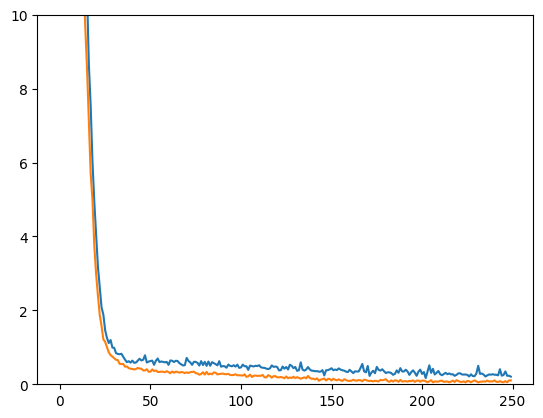

In [38]:
plt.plot(train_losses)
plt.plot(test_losses)
plt.ylim([0,10])

(array([ 2.,  9., 14., 36., 72., 58., 48., 11.,  4.,  2.]),
 array([0.26118067, 0.26722696, 0.27327329, 0.27931958, 0.28536591,
        0.2914122 , 0.2974585 , 0.30350482, 0.30955112, 0.31559744,
        0.32164374]),
 <BarContainer object of 10 artists>)

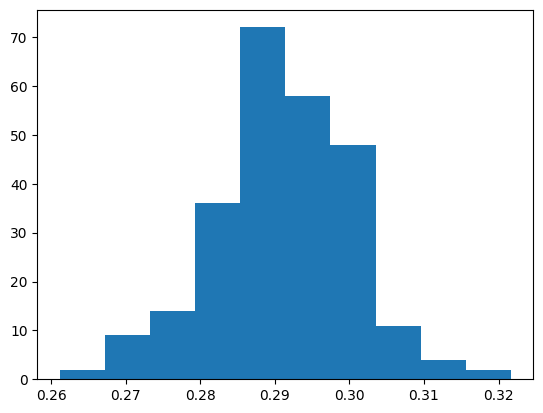

In [39]:
plt.hist(np.mean(n,axis=1))

In [20]:
preds = summarize_predictions(y_hat, A0, n)
# preds

In [21]:
preds['Q_mean'].shape

(256, 200)

In [22]:
preds['A0_static'].shape

(256,)

In [25]:
x_d.shape

(129, 200, 18)

In [24]:
subbasin_list = []
Q_prior_list = []
y_list = []
y_pred_list = []
y_pred_low_list = []
y_pred_high_list = []
A0_list = []
n_list = []
h_list = []
w_list = []
s_list = []


key = jax.random.PRNGKey(0)
keys = jax.random.split(key)

for batch in tqdm(test_loader):
    basin, subbasin, x_d, d_mask, x_s, hws, y = batch
    d_mask = d_mask[..., 0] #bandaid
    y = y[...,0]

    # y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws)
    batch_keys = jax.random.split(keys[0], x_d.shape[0])
    key = keys[1]
    y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws, batch_keys)

    preds = summarize_predictions(y_hat, A0, n)
    
    # y_hat_mean = jnp.mean(y_hat, axis=1)
    # y_hat_std = jnp.std(y_hat, axis=1)

    # A0 = jnp.mean(A0, axis=1)
    # n = jnp.mean(n, axis=1)

    q_prior_index = train_dataset.features.static.index('dis_m3_pyr')
    q_prior_denorm = train_dataset.denormalize(x_s[:,q_prior_index], 'dis_m3_pyr')

    y = test_dataset.denormalize(y, 'discharge')

    for i in range(y.shape[0]):
        mask_ids = np.where(d_mask[i,:])[0]
        n_obs = len(mask_ids)

        subbasin_list.append(np.tile(subbasin[i], n_obs))
        Q_prior_list.append(np.tile(q_prior_denorm[i], n_obs))
        y_list.append(y[i, mask_ids])
        y_pred_list.append(preds['Q_mean'][i, mask_ids])
        y_pred_low_list.append(preds['Q_low'][i, mask_ids])
        y_pred_high_list.append(preds['Q_high'][i, mask_ids])
        A0_list.append(np.tile(preds['A0_static'][i], n_obs))
        n_list.append(np.tile(preds['n_static'][i], n_obs))
        h_list.append(hws[i,mask_ids,0])
        w_list.append(hws[i,mask_ids,1])
        s_list.append(hws[i,mask_ids,2])

pred_data = {
    'subbasin': np.concatenate(subbasin_list),
    'Q_prior': np.concatenate(Q_prior_list),
    'Q_obs': np.concatenate(y_list),
    'Q_hat': np.concatenate(y_pred_list),
    'Q_hat_low': np.concatenate(y_pred_low_list),
    'Q_hat_high': np.concatenate(y_pred_high_list),
    'A0': np.concatenate(A0_list),
    'n': np.concatenate(n_list),
    'h': np.concatenate(h_list),
    'w': np.concatenate(w_list),
    's': np.concatenate(s_list),
}

raw_results = pd.DataFrame(pred_data)

100%|██████████| 3/3 [00:55<00:00, 18.49s/it]


In [25]:
raw_results

,subbasin,Q_prior,Q_obs,Q_hat,Q_hat_low,Q_hat_high,A0,n,h,w,s
0,BRANA-72849000,10.031998,31.295900,10.872776,0.000000,22.452093,0.0,0.0,-0.56135,82.019958,0.001099
1,BRANA-72849000,10.031998,319.270966,9.860230,0.000000,19.305029,0.0,0.0,0.86715,82.019958,0.001099
2,BRANA-72849000,10.031998,402.221100,6.890487,0.243685,19.463604,0.0,0.0,1.54465,82.019958,0.001099
3,BRANA-72849000,10.031998,197.435944,8.980431,0.000000,22.119553,0.0,0.0,0.33895,82.019958,0.001099
4,BRANA-72849000,10.031998,194.125061,9.793597,2.443308,16.182657,0.0,0.0,0.09465,82.019958,0.001099
...,...,...,...,...,...,...,...,...,...,...,...
32192,USGS-07151500,9.359001,3.313071,7.882690,0.742949,22.564545,0.0,0.0,0.05140,53.403168,0.000874
32193,USGS-07151500,9.359001,4.870498,13.623573,3.420538,25.821476,0.0,0.0,0.14790,53.403168,0.000874
32194,USGS-07151500,9.359001,4.700596,11.185204,0.096516,22.892551,0.0,0.0,0.10350,53.403168,0.000874
32195,USGS-07151500,9.359001,4.077626,8.187992,0.000000,21.457170,0.0,0.0,-0.01880,53.403168,0.000874


In [4]:
raw_reach_avg = raw_results.groupby('subbasin').mean()
log_ratio = np.abs(np.log10(raw_reach_avg['Q_hat'] / raw_reach_avg['Q_prior']))
good_gauges = log_ratio.index[log_ratio<0.5].tolist()

results = raw_results[raw_results['subbasin'].isin(good_gauges)]
results.to_parquet('./reach_simple_results.parquet')

NameError: name 'raw_results' is not defined

In [13]:
results = pd.read_parquet('./reach_parameter_results.parquet')

Text(0.5, 1.0, "Estimated 'n' (count = 480)")

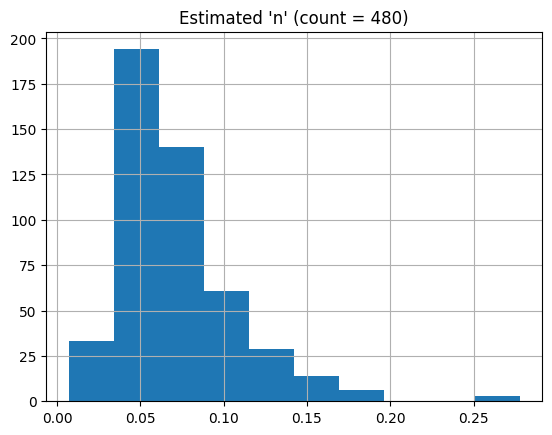

In [14]:
reach_avg = results.groupby('subbasin').mean()

reach_avg.hist('n')
plt.title(f"Estimated 'n' (count = {len(reach_avg)})")

In [15]:
from evaluate import get_basin_metrics

# Set 'subbasin' as the index to prevent its deletion, then extract target columns
df_reformatted = results.set_index('subbasin')[['Q_hat', 'Q_obs']].copy()
df_reformatted.index.name = 'subbasins'

# Assign MultiIndex to columns
df_reformatted.columns = pd.MultiIndex.from_tuples([
    ('pred', 'discharge'),
    ('obs', 'discharge')
])

metrics = get_basin_metrics(df_reformatted)

metrics.to_parquet('./reach_simple_metrics.parquet')

metrics

Feature        discharge                                                     \
Metric           num_obs        R2 spearman_r pearson_r       NSE      sigE   
ABOM-11748010         27  0.135453   0.559829  0.955931  0.135453  0.562444   
ABOM-133163010        60  0.877568   0.930759  0.974342  0.877568  0.250207   
ABOM-134884010        28  0.654874   0.929392  0.936184  0.654874  0.380326   
ABOM-135837010        43  0.927837   0.966475     0.978  0.927837  0.158354   
ABOM-138161010        28  0.352467   0.916804  0.970276  0.352467  0.466089   
...                  ...       ...        ...       ...       ...       ...   
USGS-14321000         96  0.837067   0.926329  0.946352  0.837067  0.259619   
USGS-14359000         45 -0.365754   0.936619  0.950823 -0.365754  0.214228   
USGS-15446000         90  0.509176   0.736265  0.826676  0.509176  0.326807   
USGS-15485500        143   0.01048   0.295366  0.499834   0.01048  0.703791   
USGS-15564900        108  0.312002    0.50251  0.823688  0.312002  0.788443   

Feature                                                                  \
Metric               rRMSE      MAPE      nBias          RE          RB   
ABOM-11748010    69.279712  9.033339  10.116994  1011.69939  1011.69939   
ABOM-133163010   42.106557  1.441497   0.485668   52.143168   48.526895   
ABOM-134884010   74.656528  0.502622  -0.051814   32.663906   -5.606413   
ABOM-135837010   30.513778  0.407566  -0.051046   19.430053    -5.37914   
ABOM-138161010    55.78028  2.839294   1.627048  162.677073  162.677073   
...                    ...       ...        ...         ...         ...   
USGS-14321000    59.307832  0.395263   0.228908    35.38084   22.887194   
USGS-14359000   175.679851  0.621106  -0.632525   172.12708  -172.12708   
USGS-15446000       80.074  1.538413   -0.34239   62.290466  -52.065849   
USGS-15485500   108.780694  0.913338  -0.503008  128.362679 -101.210546   
USGS-15564900   136.524689   2.00696  -0.513737  142.596745 -105.650163   

Feature                                                                    \
Metric         Agreement       KGE      corr     alpha      beta nse_prob   
ABOM-11748010   0.623854 -0.789677  0.955931  0.749996  2.771582      NaN   
ABOM-133163010  0.920753  0.688928  0.974342  0.729987  1.152317      NaN   
ABOM-134884010  0.734765  0.466137  0.936184  0.510626  0.796406      NaN   
ABOM-135837010   0.95717  0.807909     0.978  0.824493  0.925084      NaN   
ABOM-138161010  0.795262  0.024317  0.970276  1.296131  1.929183      NaN   
...                  ...       ...       ...       ...       ...      ...   
USGS-14321000   0.892829  0.694556  0.946352   0.71716  0.897925      NaN   
USGS-14359000   0.400071   0.19925  0.950823  0.478939  0.393966      NaN   
USGS-15446000    0.67936  0.494806  0.826677  0.628988  0.704145      NaN   
USGS-15485500   0.308604  0.174109  0.499834  0.441817  0.653069      NaN   
USGS-15564900   0.454717  0.224511  0.823688  0.348269  0.618499      NaN   

Feature               
Metric         MSESS  
ABOM-11748010    NaN  
ABOM-133163010   NaN  
ABOM-134884010   NaN  
ABOM-135837010   NaN  
ABOM-138161010   NaN  
...              ...  
USGS-14321000    NaN  
USGS-14359000    NaN  
USGS-15446000    NaN  
USGS-15485500    NaN  
USGS-15564900    NaN  

[480 rows x 18 columns]

In [16]:
results = results.set_index('subbasin')

In [24]:
from scipy.stats import spearmanr, pearsonr

metrics[('discharge','h_corr_p')] = np.nan
metrics[('discharge','h_corr_s')] = np.nan
for site, grp in results.groupby('subbasin'):
    metrics.loc[site,('discharge','h_corr_p')] = pearsonr(grp['h'], grp['Q_obs']).statistic
    metrics.loc[site,('discharge','h_corr_s')] = spearmanr(grp['h'], grp['Q_obs']).statistic


In [25]:
metrics

Feature        discharge                                                     \
Metric           num_obs        R2 spearman_r pearson_r       NSE      sigE   
ABOM-11748010         27  0.135453   0.559829  0.955931  0.135453  0.562444   
ABOM-133163010        60  0.877568   0.930759  0.974342  0.877568  0.250207   
ABOM-134884010        28  0.654874   0.929392  0.936184  0.654874  0.380326   
ABOM-135837010        43  0.927837   0.966475     0.978  0.927837  0.158354   
ABOM-138161010        28  0.352467   0.916804  0.970276  0.352467  0.466089   
...                  ...       ...        ...       ...       ...       ...   
USGS-14321000         96  0.837067   0.926329  0.946352  0.837067  0.259619   
USGS-14359000         45 -0.365754   0.936619  0.950823 -0.365754  0.214228   
USGS-15446000         90  0.509176   0.736265  0.826676  0.509176  0.326807   
USGS-15485500        143   0.01048   0.295366  0.499834   0.01048  0.703791   
USGS-15564900        108  0.312002    0.50251  0.823688  0.312002  0.788443   

Feature                                                      ...            \
Metric               rRMSE      MAPE      nBias          RE  ... Agreement   
ABOM-11748010    69.279712  9.033339  10.116994  1011.69939  ...  0.623854   
ABOM-133163010   42.106557  1.441497   0.485668   52.143168  ...  0.920753   
ABOM-134884010   74.656528  0.502622  -0.051814   32.663906  ...  0.734765   
ABOM-135837010   30.513778  0.407566  -0.051046   19.430053  ...   0.95717   
ABOM-138161010    55.78028  2.839294   1.627048  162.677073  ...  0.795262   
...                    ...       ...        ...         ...  ...       ...   
USGS-14321000    59.307832  0.395263   0.228908    35.38084  ...  0.892829   
USGS-14359000   175.679851  0.621106  -0.632525   172.12708  ...  0.400071   
USGS-15446000       80.074  1.538413   -0.34239   62.290466  ...   0.67936   
USGS-15485500   108.780694  0.913338  -0.503008  128.362679  ...  0.308604   
USGS-15564900   136.524689   2.00696  -0.513737  142.596745  ...  0.454717   

Feature                                                                \
Metric               KGE      corr     alpha      beta nse_prob MSESS   
ABOM-11748010  -0.789677  0.955931  0.749996  2.771582      NaN   NaN   
ABOM-133163010  0.688928  0.974342  0.729987  1.152317      NaN   NaN   
ABOM-134884010  0.466137  0.936184  0.510626  0.796406      NaN   NaN   
ABOM-135837010  0.807909     0.978  0.824493  0.925084      NaN   NaN   
ABOM-138161010  0.024317  0.970276  1.296131  1.929183      NaN   NaN   
...                  ...       ...       ...       ...      ...   ...   
USGS-14321000   0.694556  0.946352   0.71716  0.897925      NaN   NaN   
USGS-14359000    0.19925  0.950823  0.478939  0.393966      NaN   NaN   
USGS-15446000   0.494806  0.826677  0.628988  0.704145      NaN   NaN   
USGS-15485500   0.174109  0.499834  0.441817  0.653069      NaN   NaN   
USGS-15564900   0.224511  0.823688  0.348269  0.618499      NaN   NaN   

Feature                                       
Metric            h_corr  h_corr_p  h_corr_s  
ABOM-11748010   0.559829  0.938162  0.559829  
ABOM-133163010  0.930759  0.936556  0.930759  
ABOM-134884010  0.929392  0.895030  0.929392  
ABOM-135837010  0.966475  0.967156  0.966475  
ABOM-138161010  0.916804  0.936035  0.916804  
...                  ...       ...       ...  
USGS-14321000   0.926329  0.940860  0.926329  
USGS-14359000   0.936619  0.953917  0.936619  
USGS-15446000   0.736265  0.833495  0.736265  
USGS-15485500   0.295366  0.471637  0.295366  
USGS-15564900   0.502510  0.788770  0.502510  

[480 rows x 21 columns]

(-1.0, 1.0)

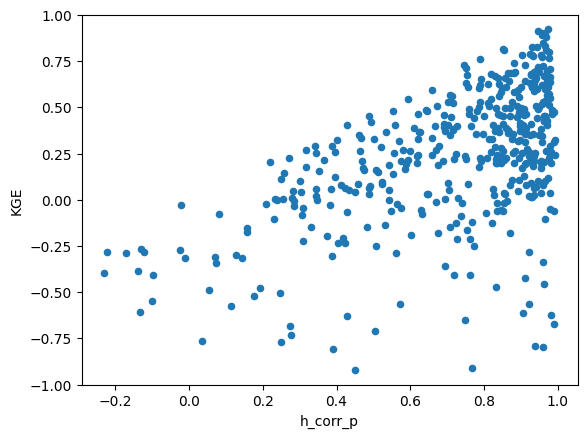

In [28]:
metrics['discharge'].plot.scatter('h_corr_p', 'KGE')
plt.ylim([-1,1])

In [29]:
basin_results = results[results['subbasin'] == 'ABOM-138161010']

basin_results.plot.scatter('Q_obs','Q_hat')

KeyError: 'subbasin'

In [ ]:
basin_results

<Axes: xlabel='h', ylabel='w'>

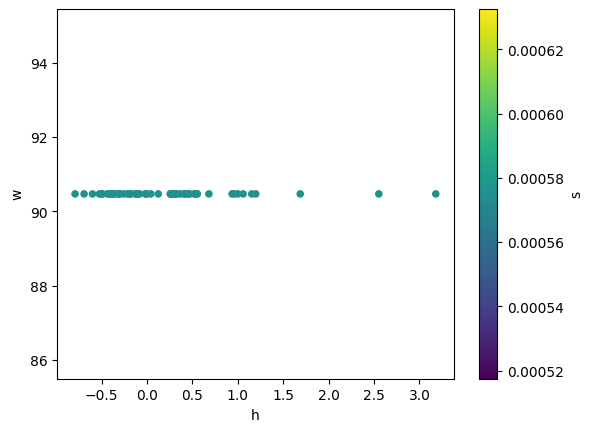

In [69]:
basin_results.plot.scatter('h','w', c='s')